# Chapter 3 · Frames and Homogeneous Transforms

**Companion notebook to *Mathematics for Robotics: A Beginner's Guide*** · ROSFORGE · rosforge.com

Read Chapter 3 of the book, then run each cell here to see the idea at work. Change the numbers and re-run: that is the fastest way to build intuition. Section numbers below match the book.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.figsize"] = (5, 5)
deg = np.pi / 180

def R2(a):
    c, s = np.cos(a), np.sin(a); return np.array([[c, -s], [s, c]])

def T2(R, p):
    # 3x3 homogeneous transform for 2D: rotation R (2x2) and position p
    T = np.eye(3); T[:2, :2] = R; T[:2, 2] = p; return T

def draw_frame2d(ax, T, scale=0.5, label=""):
    o = T[:2, 2]
    ax.annotate("", xy=o + scale * T[:2, 0], xytext=o, arrowprops=dict(arrowstyle="->", color="r", lw=2))
    ax.annotate("", xy=o + scale * T[:2, 1], xytext=o, arrowprops=dict(arrowstyle="->", color="g", lw=2))
    ax.text(*(o - 0.15), label)

def setup2d(ax, lim=3, title=""):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(alpha=.3); ax.set_title(title)

## 3.1 and 3.2 A shift is not a matrix; the fix is to pad with a 1
A matrix always fixes the origin, so *rotate then shift* is not linear. Pad every point with a $1$, and one matrix $T=\begin{bmatrix}R&p\\0&1\end{bmatrix}$ does both. Chaining motions becomes ordinary matrix multiplication.

In [2]:
p = np.array([3, -1])
T = np.array([[1, 0, 3], [0, 1, -1], [0, 0, 1]])          # pure shift by (3, -1)
print("(2,2) shifted by (3,-1):", (T @ [2, 2, 1])[:2])

T = T2(R2(90 * deg), [1, 0])                             # rotate 90 deg, then shift by (1, 0)
print("T =\n", T)
print("T (1,0,1) =", T @ [1, 0, 1], " -> the point (1,1): rotated (1,0) to (0,1), then added (1,0)")

(2,2) shifted by (3,-1): [5 1]
T =
 [[ 0. -1.  1.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]]
T (1,0,1) = [1. 1. 1.]  -> the point (1,1): rotated (1,0) to (0,1), then added (1,0)


## 3.3 Frames and chains of transforms (this is what ROS `tf2` does)
$T_{AC}=T_{AB}\,T_{BC}$. A mobile robot in a map carries a lidar; the lidar sees an obstacle; where is it in the map?

obstacle in the map frame: [2.  3.3]


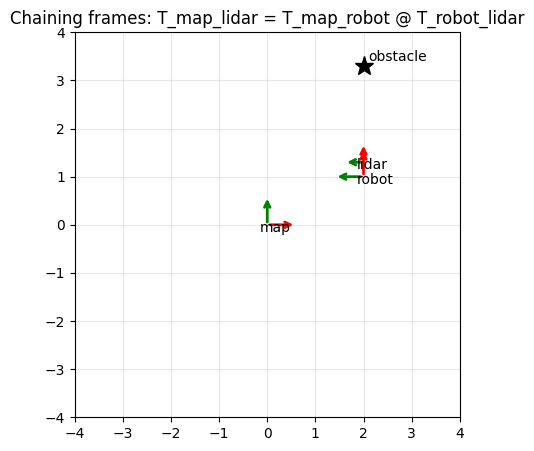

In [3]:
T_map_robot = T2(R2(90 * deg), [2, 1])        # robot in the map
T_robot_lidar = T2(np.eye(2), [0.3, 0])       # lidar in the robot frame (0.3 m forward)
p_lidar = np.array([2, 0, 1])                 # obstacle in the lidar frame (homogeneous)

T_map_lidar = T_map_robot @ T_robot_lidar     # chain the frames
p_map = T_map_lidar @ p_lidar
print("obstacle in the map frame:", p_map[:2])

fig, ax = plt.subplots()
draw_frame2d(ax, np.eye(3), 0.6, "map"); draw_frame2d(ax, T_map_robot, 0.6, "robot"); draw_frame2d(ax, T_map_lidar, 0.4, "lidar")
ax.plot(*p_map[:2], "k*", ms=14); ax.text(*(p_map[:2] + 0.1), "obstacle"); setup2d(ax, 4, "Chaining frames: T_map_lidar = T_map_robot @ T_robot_lidar"); plt.show()

## 3.4 Undoing a transform
$T^{-1}=\begin{bmatrix}R^\top&-R^\top p\\0&1\end{bmatrix}$.

In [4]:
def inv_T(T):
    n = T.shape[0] - 1; R, p = T[:n, :n], T[:n, n]
    Ti = np.eye(n + 1); Ti[:n, :n] = R.T; Ti[:n, n] = -R.T @ p; return Ti

print("T @ T^-1 = I:", np.allclose(T_map_robot @ inv_T(T_map_robot), np.eye(3)))
print("obstacle as seen from the robot frame:", (inv_T(T_map_robot) @ np.append(p_map[:2], 1))[:2])

T @ T^-1 = I: True
obstacle as seen from the robot frame: [2.3 0. ]


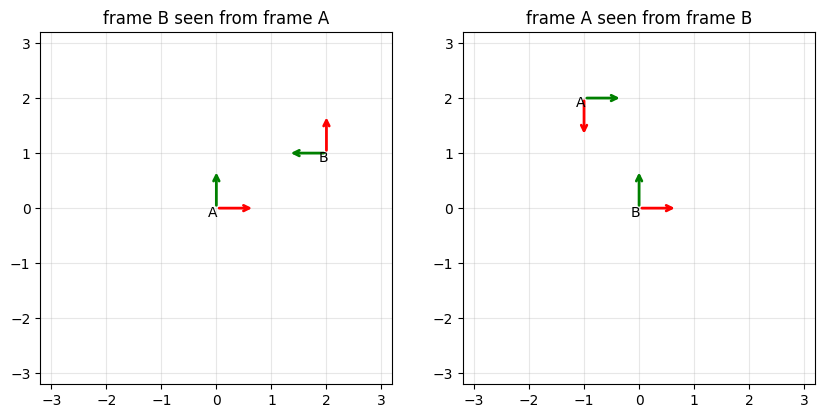

A as seen from B sits at -R^T p = [-1.  2.]


In [5]:
# the same pair of frames, seen from each side
T_AB = T2(R2(90 * deg), [2, 1]); T_BA = inv_T(T_AB)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, (Tm, fa, fb) in zip(axes, [(T_AB, "A", "B"), (T_BA, "B", "A")]):
    draw_frame2d(ax, np.eye(3), 0.7, fa); draw_frame2d(ax, Tm, 0.7, fb); setup2d(ax, 3.2, f"frame {fb} seen from frame {fa}")
plt.show()
print("A as seen from B sits at -R^T p =", T_BA[:2, 2])

## 3.5 Three ways to read the same matrix
A transform can be read as (1) a description of a frame, (2) a change of coordinates, (3) an operator that moves points. The numbers are identical; only the interpretation changes. Below, the same $T$ is used all three ways.

In [6]:
T_AB = T2(R2(90 * deg), [2, 1])
P_B = np.array([1, 0, 1.])                       # a point with coordinates (1,0) in frame B
print("1. frame:       B sits at", T_AB[:2, 2], "with its x-axis pointing along", T_AB[:2, 0])
print("2. coordinates: the point (1,0) in B has coordinates", (T_AB @ P_B)[:2], "in A")
print("3. operator:    T moves the point (1,0) of A to", (T_AB @ P_B)[:2])

1. frame:       B sits at [2. 1.] with its x-axis pointing along [0. 1.]
2. coordinates: the point (1,0) in B has coordinates [2. 2.] in A
3. operator:    T moves the point (1,0) of A to [2. 2.]


## 3.6 Transforms in space
The same idea one dimension up: $4\times4$ matrices built from a $3\times3$ rotation and a 3-vector.

In [7]:
def Rz3(a): c, s = np.cos(a), np.sin(a); return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])
def Rx3(a): c, s = np.cos(a), np.sin(a); return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

def T3(R, p):
    T = np.eye(4); T[:3, :3] = R; T[:3, 3] = p; return T
def rot_z(a): return T3(Rz3(a), [0, 0, 0])
def rot_x(a): return T3(Rx3(a), [0, 0, 0])
def trans(x, y, z): return T3(np.eye(3), [x, y, z])

T = T3(Rz3(0.7) @ Rx3(0.3), [1, 2, 3]); x = np.array([0.5, -1.0, 2.0])
print("T [x;1] = [Rx + p; 1]:", np.allclose(T @ np.append(x, 1), np.append(T[:3, :3] @ x + T[:3, 3], 1)))
print("T @ T^-1 = I:", np.allclose(T @ inv_T(T), np.eye(4)))

T [x;1] = [Rx + p; 1]: True
T @ T^-1 = I: True


In [8]:
T = T3(Rz3(90 * deg), [1, 2, 3])
print("(1,0,0) in B is at", (T @ [1, 0, 0, 1])[:3], "in A   (book: (1,3,3))")

(1,0,0) in B is at [1. 3. 3.] in A   (book: (1,3,3))


---
## Exercises

> **Exercise 3.1**
>
> Frame $B$ is at $(2,1)$ in frame $A$ and rotated $90^\circ$. A point has coordinates $(1,0)$ in $B$. What are its coordinates in $A$?

In [9]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 3.1** *(this is the book's Appendix B, checked in code)*

In [10]:
p = (T2(R2(90*deg), [2, 1]) @ [1, 0, 1])[:2]; print(p.round(6)); assert np.allclose(p, [2, 2])

[2. 2.]


> **Exercise 3.2**
>
> Find the inverse of $T=\begin{bmatrix}0&-1&1\\1&0&0\\0&0&1\end{bmatrix}$ with the block formula and check $TT^{-1}=I$.

In [11]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 3.2** *(this is the book's Appendix B, checked in code)*

In [12]:
T = np.array([[0, -1, 1], [1, 0, 0], [0, 0, 1.]]); Ti = inv_T(T); print(Ti.round(6)); assert np.allclose(Ti, [[0, 1, 0], [-1, 0, 1], [0, 0, 1]]) and np.allclose(T @ Ti, np.eye(3))

[[ 0.  1.  0.]
 [-1.  0.  1.]
 [ 0.  0.  1.]]


> **Exercise 3.3**
>
> A robot is at $(1,2)$ in the map, turned $180^\circ$. A point has coordinates $(1,1)$ in the robot frame. Where is it in the map?

In [13]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 3.3** *(this is the book's Appendix B, checked in code)*

In [14]:
p = (T2(R2(180*deg), [1, 2]) @ [1, 1, 1])[:2]; print(p.round(6)); assert np.allclose(p, [0, 1])

[-0.  1.]


> **Exercise 3.4**
>
> $T_{AB}$ is a pure shift by $(1,0)$ and $T_{BC}$ a pure $90^\circ$ rotation about the origin of $B$. Where, in $A$, is the point $(1,0)$ given in $C$?

In [15]:
# Your work here (try the exercise before looking at the solution cell below)

**Solution 3.4** *(this is the book's Appendix B, checked in code)*

In [16]:
p = (T2(np.eye(2), [1, 0]) @ T2(R2(90*deg), [0, 0]) @ [1, 0, 1])[:2]; print(p.round(6)); assert np.allclose(p, [1, 1])

[1. 1.]


---
**Next:** `04_Forward_Kinematics.ipynb` (Chapter 4)

*Mathematics for Robotics: A Beginner's Guide* · ROSFORGE · rosforge.com